In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pylab as pl

In [3]:
df = pd.read_csv('../data/FuelConsumption.csv')
df.head(9)

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244
5,2014,ACURA,RLX,MID-SIZE,3.5,6,AS6,Z,11.9,7.7,10.0,28,230
6,2014,ACURA,TL,MID-SIZE,3.5,6,AS6,Z,11.8,8.1,10.1,28,232
7,2014,ACURA,TL AWD,MID-SIZE,3.7,6,AS6,Z,12.8,9.0,11.1,25,255
8,2014,ACURA,TL AWD,MID-SIZE,3.7,6,M6,Z,13.4,9.5,11.6,24,267


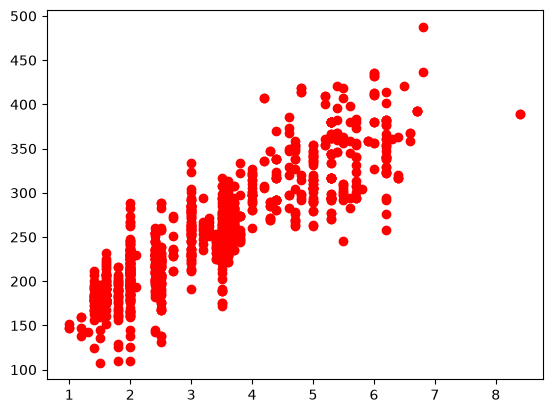

In [4]:
plt.scatter(df.ENGINESIZE,df.CO2EMISSIONS,color='red')
plt.show()

In [5]:
msk = np.random.rand(len(df)) < 0.8
train = df[msk]
test = df[~msk]

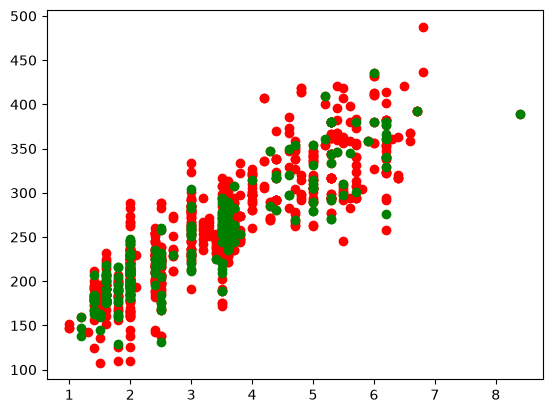

In [8]:
plt.scatter(train.ENGINESIZE,train.CO2EMISSIONS,color='red')
plt.scatter(test.ENGINESIZE,test.CO2EMISSIONS,color='green')

plt.show()

In [14]:
from sklearn import linear_model
regr = linear_model.LinearRegression()
train_x = np.asanyarray(train[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB']])
train_y = np.asanyarray(train[['CO2EMISSIONS']])
regr.fit(train_x,train_y)
print('Coef-->', regr.coef_)
print('Intercept-->',regr.intercept_)

Coef--> [[10.19396863  7.7443953   9.81983688]]
Intercept--> [64.09385981]


In [17]:

test_x = np.asanyarray(test[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB']])
y_hat = regr.predict(test_x)
test_y = np.asanyarray(test[['CO2EMISSIONS']])
residual_sum = np.mean((y_hat - test_y) ** 2 )
print('residual sum of squares',residual_sum)

print('variance score: %.2f' % regr.score(test_x,test_y))

residual sum of squares 538.217066474656
variance score: 0.86


In [18]:
from sklearn import linear_model
regr = linear_model.LinearRegression()
train_x = np.asanyarray(train[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_CITY','FUELCONSUMPTION_HWY']])
train_y = np.asanyarray(train[['CO2EMISSIONS']])
regr.fit(train_x,train_y)
print('Coef-->', regr.coef_)
print('Intercept-->',regr.intercept_)

Coef--> [[10.289721    7.3339251   6.42415024  3.06089646]]
Intercept--> [65.44954242]


In [19]:

test_x = np.asanyarray(test[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_CITY','FUELCONSUMPTION_HWY']])
y_hat = regr.predict(test_x)
test_y = np.asanyarray(test[['CO2EMISSIONS']])
residual_sum = np.mean((y_hat - test_y) ** 2 )
print('residual sum of squares',residual_sum)

print('variance score: %.2f' % regr.score(test_x,test_y))

residual sum of squares 539.1631704812343
variance score: 0.86
